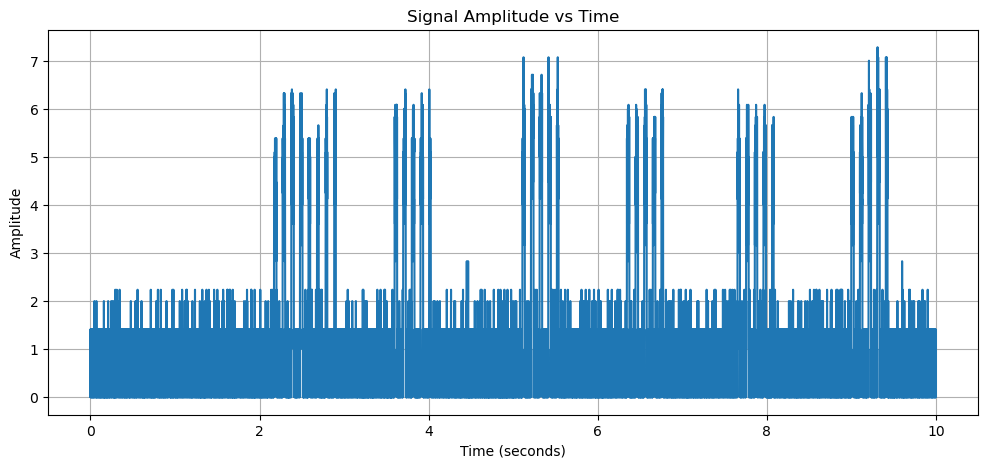

In [49]:
import numpy as np 
from pathlib import Path 
from load_file import load_file
import matplotlib.pyplot as plt

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\mycarfreq_10sec.bin")

samples = load_file(file_path)

# Original sample rate 
fs = 2_048_000  # sampling freq 

time = np.arange(1, len(samples) + 1)/ fs 

plt.figure(figsize=(12, 5))
plt.plot(time[::1000], np.abs(samples[::1000])) 

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude") 
plt.title("Signal Amplitude vs Time") 
plt.grid(True) 
plt.show() 


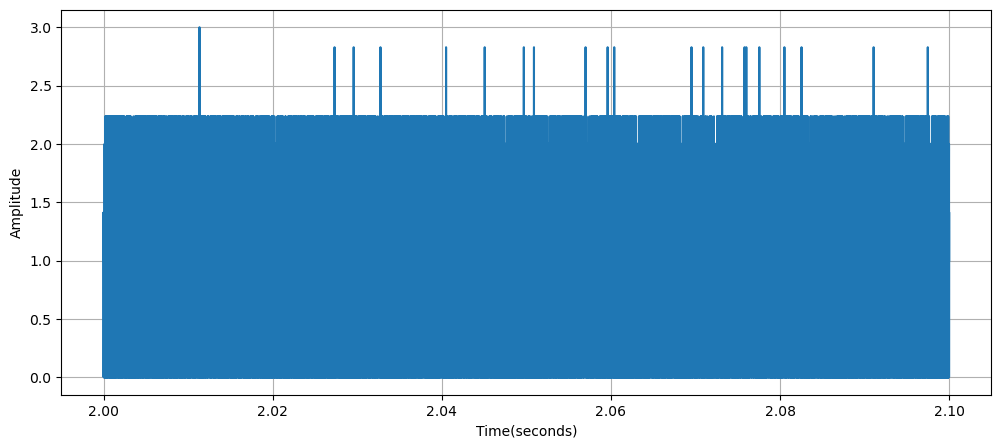

In [50]:
plt.figure(figsize=(12, 5))
plt.plot(time[int(2 * fs):int(2.1 * fs)], np.abs(samples[int(2 * fs):int(2.1 *fs)])) 

plt.xlabel("Time(seconds)") 
plt.ylabel("Amplitude") 
plt.grid(True) 
plt.show() 

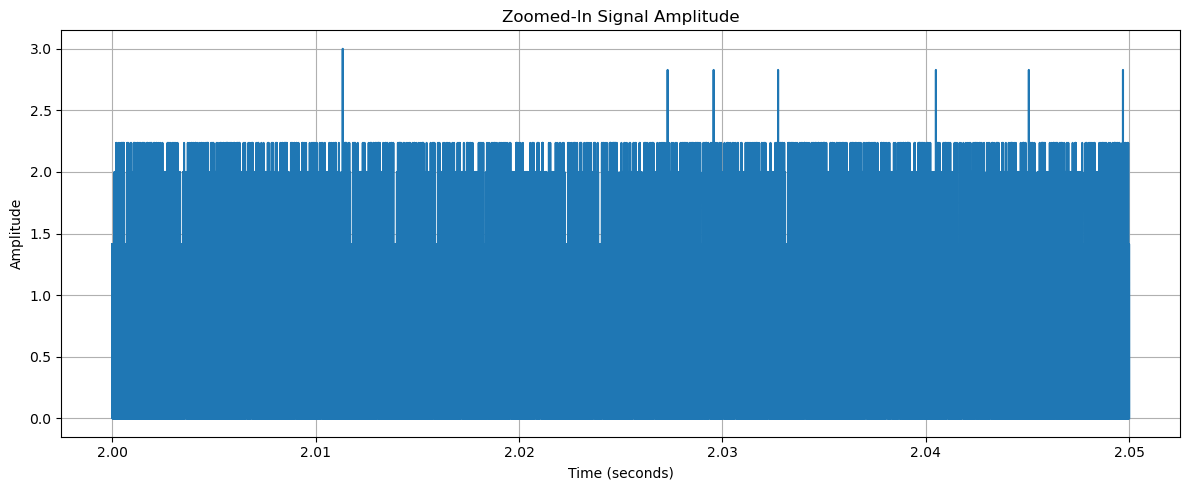

In [51]:
# Zoom in from 2.00 to 2.01 seconds
start = int(2.00 * fs)
end = int(2.05 * fs)

plt.figure(figsize=(12, 5))
plt.plot(time[start:end], np.abs(samples[start:end]))

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Zoomed-In Signal Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

In [52]:
# Calculate the signal magnitude
dd_samples = np.abs(samples)


# Display amplitude range
print("Minimum amplitude:", np.min(dd_samples))
print("Maximum amplitude:", np.max(dd_samples))


Minimum amplitude: 0.0
Maximum amplitude: 8.602325267042627


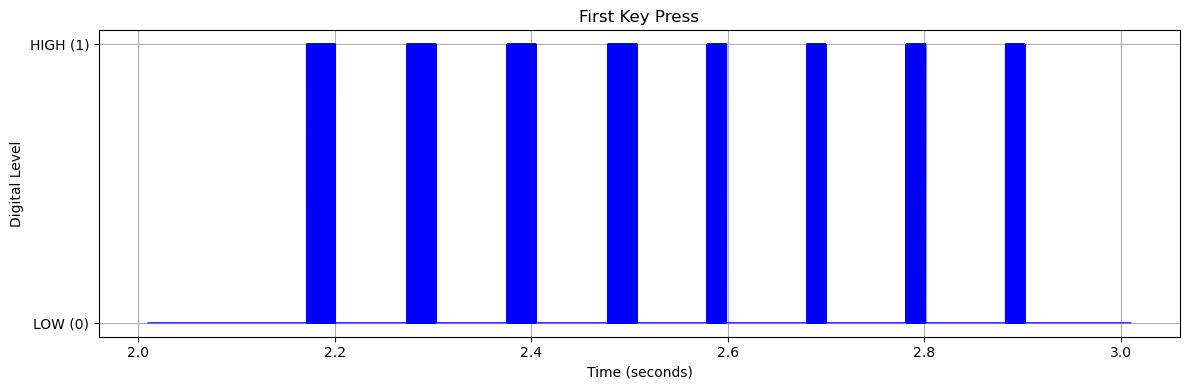

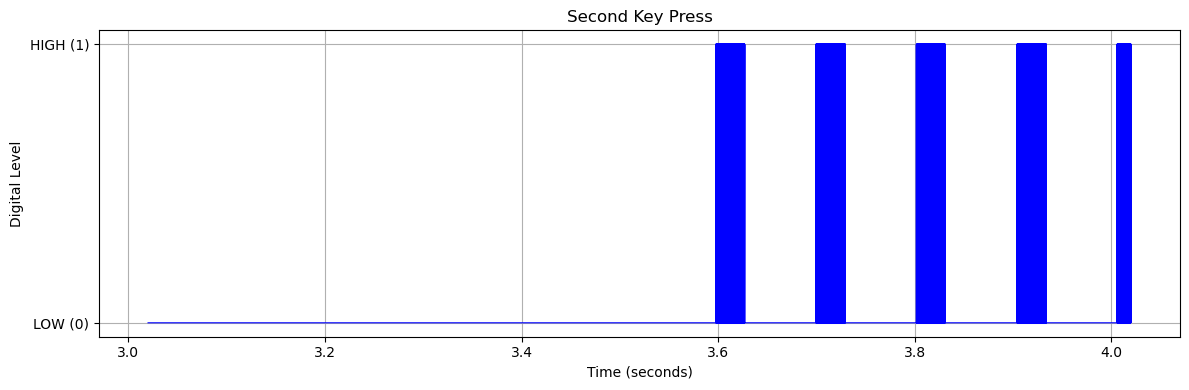

In [53]:
# Apply the decision threshold
threshold = 4
dd_digital = (dd_samples > threshold).astype(int)


# Plot the first key press
start = int(2.01 * fs)
end = int(3.01 * fs)

plt.figure(figsize=(12, 4))
plt.plot(time[start:end], dd_digital[start:end],
         color="blue", linewidth=0.8, drawstyle="steps-post")

plt.xlabel("Time (seconds)")
plt.ylabel("Digital Level")
plt.title("First Key Press")
plt.yticks([0, 1], ["LOW (0)", "HIGH (1)"])
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot the second key press
start2 = int(3.02 * fs)
end2 = int(4.02 * fs)

plt.figure(figsize=(12, 4))
plt.plot(time[start2:end2], dd_digital[start2:end2],
         color="blue", linewidth=0.8, drawstyle="steps-post")

plt.xlabel("Time (seconds)")
plt.ylabel("Digital Level")
plt.title("Second Key Press")
plt.yticks([0, 1], ["LOW (0)", "HIGH (1)"])
plt.grid(True)
plt.tight_layout()
plt.show()

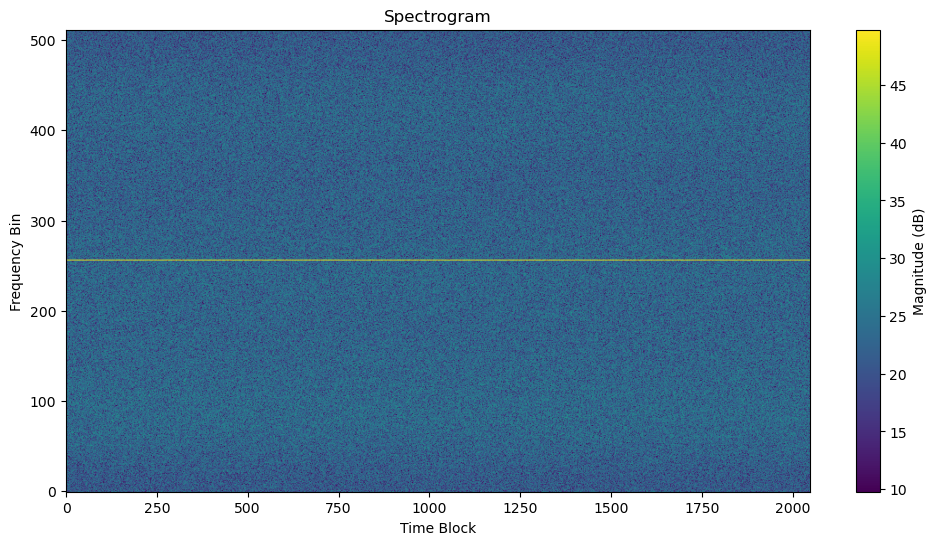

In [54]:
from msg import msg

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\921ismband.bin")

ism_samples = load_file(file_path)

# Original sample rate 
fs = 2_048_000  # sampling freq

spectrum = msg(ism_samples, 1, 512, 2048)

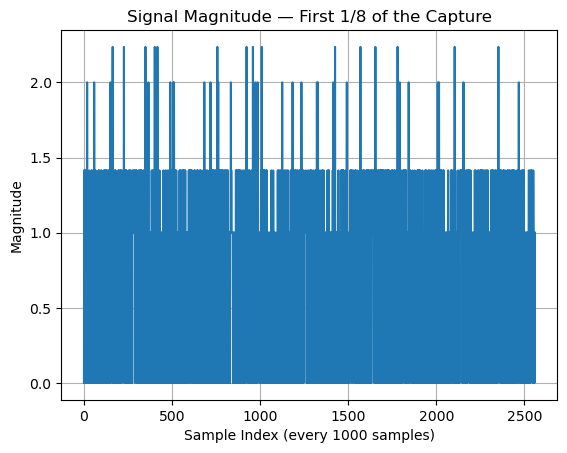

In [55]:
# Plot the magnitude of every 1000th sample
# from the first 1/8 of the signal
plt.plot(np.abs(ism_samples[:len(ism_samples) // 8:1000]))

plt.xlabel("Sample Index (every 1000 samples)")
plt.ylabel("Magnitude")
plt.title("Signal Magnitude — First 1/8 of the Capture")
plt.grid(True)
plt.show()

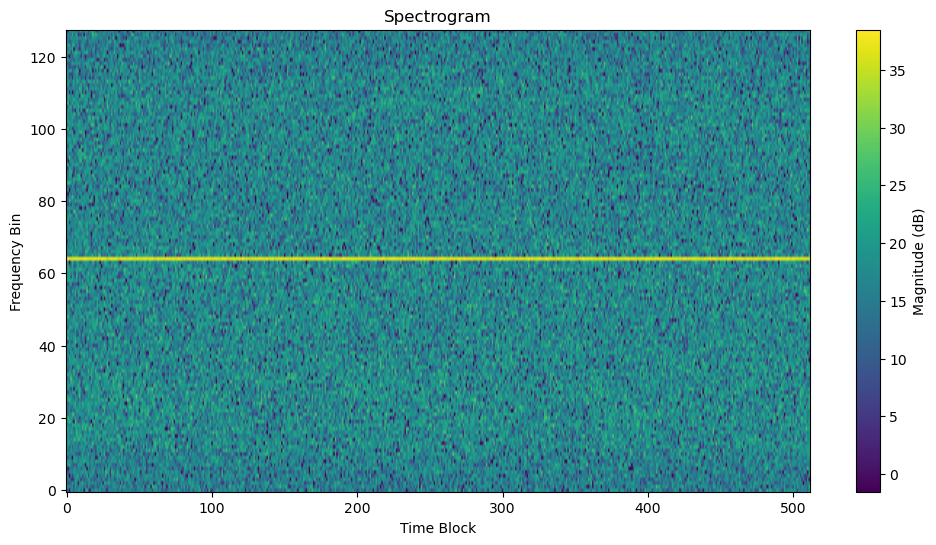

In [56]:
dd_samples = msg(ism_samples, 1160000, 128, 512, 20)

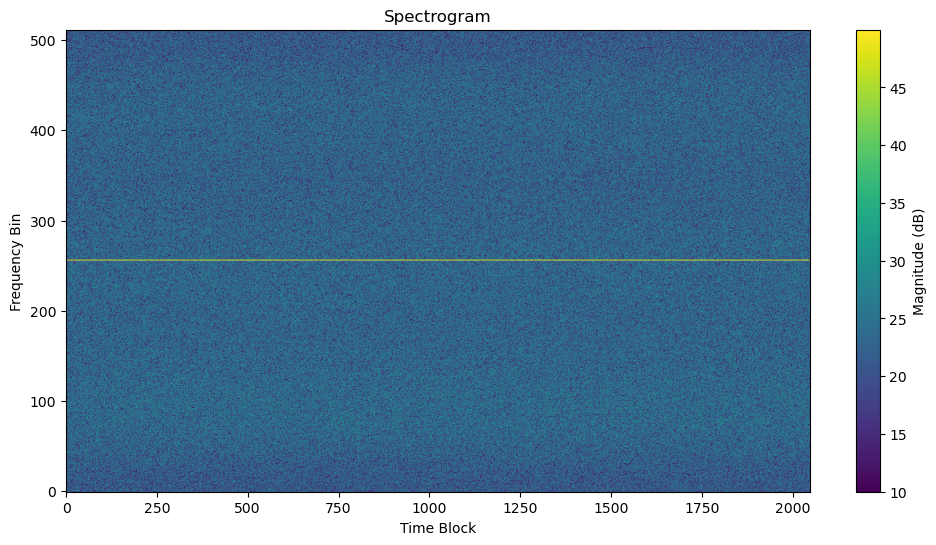

In [57]:
from msg import msg

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\nfm154875.bin")

dr_samples = load_file(file_path)

# Original sample rate 
fs = 2_048_000  # sampling freq

spectrum = msg(dr_samples, 1, 512, 2048, 30)


In [58]:
from ffreq import ffreq

freq = ffreq(
    dr_samples, 
    fs=2_048_000,
    fr=1_000,
    dt=0.1,
    sq=0.1
)

print("\Detected frequency offsets (Hz):")
print(freq)

\Detected frequency offsets (Hz):
[-722000. -713000. -642000. -631000. -621000. -589000. -564000. -506000.
 -487000. -392000. -384000.  -90000.  -44000.       0.   13000.  143000.
  683000.  686000. 1020000.]


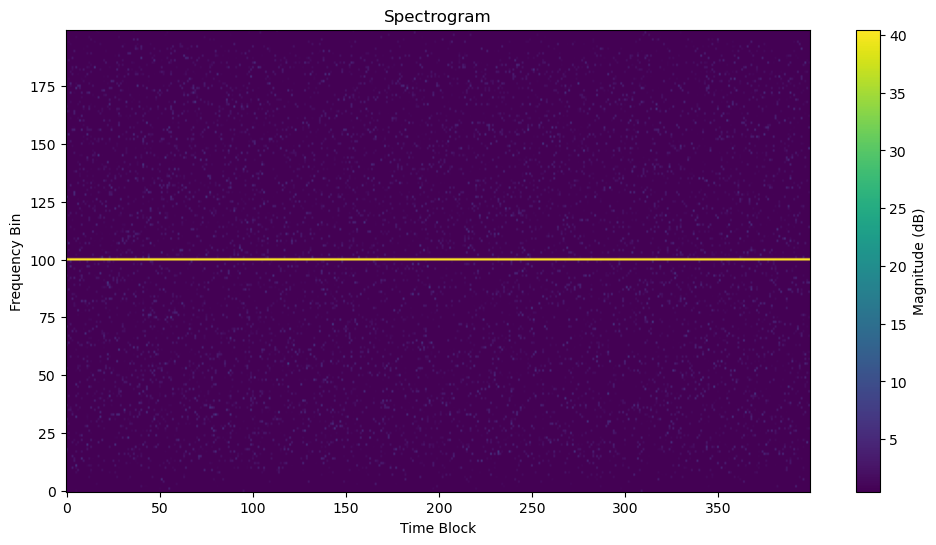

In [59]:
from scipy.signal import decimate 

### DECIMATION ###

# First decimation by 8 / Reduces IQ sample rate 
dmd = decimate(dr_samples, 8, ftype="fir")  # 2.048 MSPS to 256 kSPS

# Second decimation by 8 
dfm = decimate(dmd, 8, ftype="fir") # 256 kSPS to 32 kSPS

dtd = decimate(dfm, 4, ftype="fir") # 32 kSPS to 8 kSPS

spectrum = msg(dtd, 1, 200, 400)

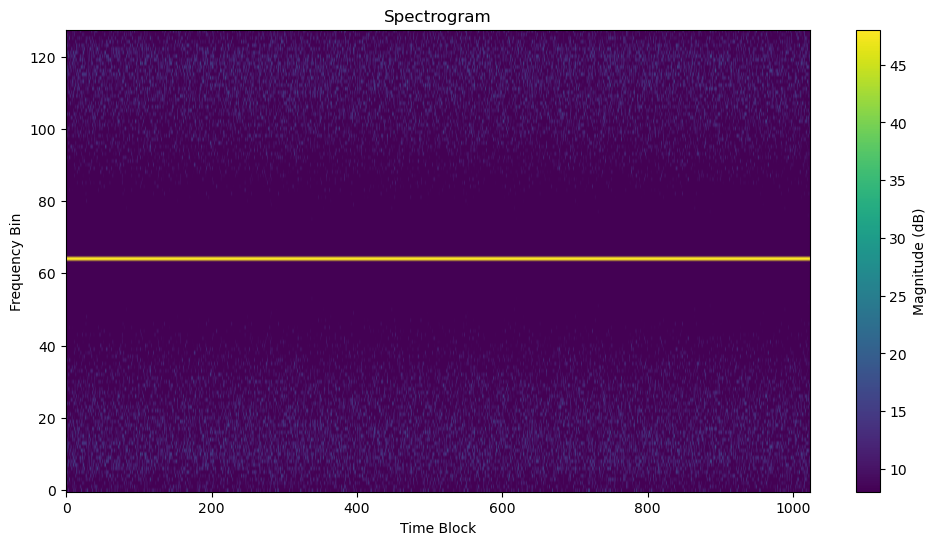

In [60]:
import numpy as np

fs = 32_000

# Shift the signal by -10 kHz
t = np.arange(len(dfm)) / fs
dfm_shifted = dfm * np.exp(-1j * 2 * np.pi * 10_000 * t)

# FM demodulation
fm_demod = np.angle(
    np.conj(dfm_shifted[:-1]) * dfm_shifted[1:]
)

# Spectrogram block size
nf = 128
nt = min(1024, len(fm_demod) // nf)

spectrum = msg(fm_demod, 1, 128, 1024, fs=32000)